In [1]:
import pandas as pd
import pickle
import os
import time

import math
import random
import shutil
import pathlib
import seaborn as sns
import numpy as np
from numpy import where
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib import pyplot
import os
import time
from imblearn.over_sampling import ADASYN
from collections import (Counter, defaultdict)
import tensorflow as tf
from scipy import stats
from tensorflow.keras import layers
#from tensorflow.python import train
from keras.models import Sequential
from keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE
import keras.callbacks as kcallbacks
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import (QuantileTransformer, LabelEncoder)
from sklearn.metrics import (det_curve, balanced_accuracy_score, cohen_kappa_score, hinge_loss, matthews_corrcoef, 
                             top_k_accuracy_score, hamming_loss, jaccard_score, log_loss, zero_one_loss, classification_report,
                             accuracy_score, precision_score, roc_auc_score, average_precision_score, recall_score, f1_score, 
                             mean_squared_error, mean_absolute_error, confusion_matrix, r2_score)

2024-02-08 20:25:52.983079: I tensorflow/core/util/port.cc:111] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-02-08 20:25:53.021312: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-02-08 20:25:53.021331: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-02-08 20:25:53.021349: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-02-08 20:25:53.028444: I tensorflow/core/platform/cpu_feature_g

# InceptionV3 model

In [ ]:
img_height = 224
img_width = 224

train_ds = tf.data.Dataset.load("saved_data/train")
val_ds = tf.data.Dataset.load("saved_data/validation")
test_ds = tf.data.Dataset.load("saved_data/test")

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

In [272]:
IMG_SHAPE = (img_height, img_width,3)
base_model_InceptionV3 = tf.keras.applications.InceptionV3(input_shape=IMG_SHAPE,
                                               include_top=False,   
                                               weights='imagenet')

In [273]:
base_model_InceptionV3.trainable = False
base_model_InceptionV3.summary()

Model: "inception_v3"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_37 (InputLayer)       [(None, 224, 224, 3)]        0         []                            
                                                                                                  
 conv2d_1692 (Conv2D)        (None, 111, 111, 32)         864       ['input_37[0][0]']            
                                                                                                  
 batch_normalization_1692 (  (None, 111, 111, 32)         96        ['conv2d_1692[0][0]']         
 BatchNormalization)                                                                              
                                                                                                  
 activation_1692 (Activatio  (None, 111, 111, 32)         0         ['batch_normalizati

In [274]:
image_batch, label_batch = next(iter(train_ds))
feature_batch_InceptionV3 = base_model_InceptionV3(image_batch)
print(feature_batch_InceptionV3.shape)
global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
feature_batch_average_InceptionV3 = global_average_layer(feature_batch_InceptionV3)
print(feature_batch_average_InceptionV3.shape)
prediction_layer_InceptionV3 = tf.keras.layers.Dense(1)
prediction_batch_InceptionV3 = prediction_layer_InceptionV3(feature_batch_average_InceptionV3)
print(prediction_batch_InceptionV3.shape)

(32, 5, 5, 2048)
(32, 2048)
(32, 1)


In [275]:
inputs_InceptionV3 = tf.keras.Input(shape=(img_height, img_width,3))
x_InceptionV3 = data_augmentation(inputs_InceptionV3)
x_InceptionV3 = tf.keras.applications.inception_v3.preprocess_input (x_InceptionV3) 
x_InceptionV3 = base_model_InceptionV3(x_InceptionV3, training=False) 
x_InceptionV3 = global_average_layer(x_InceptionV3)
x_InceptionV3 = tf.keras.layers.Dropout(0.2)(x_InceptionV3) 
outputs_InceptionV3 = prediction_layer_InceptionV3(x_InceptionV3)
model_InceptionV3 = tf.keras.Model(inputs_InceptionV3, outputs_InceptionV3)

In [276]:
class LossHistory(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs={}):
        self.losses = {'batch':[], 'epoch':[]}
        self.accuracy = {'batch':[], 'epoch':[]}
        self.val_loss = {'batch':[], 'epoch':[]}
        self.val_acc = {'batch':[], 'epoch':[]}
        self.history = {}
    def on_batch_end(self, batch, logs={}):
        self.losses['batch'].append(logs.get('loss'))
        self.accuracy['batch'].append(logs.get('accuracy'))
        self.val_loss['batch'].append(logs.get('val_loss'))
        self.val_acc['batch'].append(logs.get('val_accuracy'))
    def on_epoch_end(self, batch, logs={}):
        self.losses['epoch'].append(logs.get('loss'))
        self.accuracy['epoch'].append(logs.get('accuracy'))
        self.val_loss['epoch'].append(logs.get('val_loss'))
        self.val_acc['epoch'].append(logs.get('val_accuracy'))
        self.history = {'loss': self.losses, 'accuracy': self.accuracy, 'val_loss': self.val_loss, 'val_accuracy': self.val_acc}

In [277]:
import keras.callbacks as kcallbacks
from tensorflow.keras.callbacks import EarlyStopping

history= LossHistory()
base_learning_rate = 0.00007
savepath='./InceptionV3.h5'
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
saveBestModel = kcallbacks.ModelCheckpoint(filepath=savepath, verbose=1, 
                                               save_best_only=True, mode='auto')
model_InceptionV3.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate),
              loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [278]:
model_InceptionV3.summary()

Model: "model_18"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_38 (InputLayer)       [(None, 224, 224, 3)]     0         
                                                                 
 sequential (Sequential)     (None, 224, 224, 3)       0         
                                                                 
 tf.math.truediv_18 (TFOpLa  (None, 224, 224, 3)       0         
 mbda)                                                           
                                                                 
 tf.math.subtract_18 (TFOpL  (None, 224, 224, 3)       0         
 ambda)                                                          
                                                                 
 inception_v3 (Functional)   (None, 5, 5, 2048)        21802784  
                                                                 
 global_average_pooling2d_8  (None, 2048)              0  

In [279]:
initial_epochs = 5
loss0, accuracy0 = model_InceptionV3.evaluate(val_ds)

36/36 [==============================] - 3s 31ms/step - loss: 0.6452 - accuracy: 0.7531


In [280]:
print("initial loss: {:.4f}".format(loss0))
print("initial accuracy: {:.4f}".format(accuracy0))

initial loss: 0.6452
initial accuracy: 0.7531


In [281]:
%%time
history_InceptionV3 = model_InceptionV3.fit(train_ds, epochs=initial_epochs, validation_data=val_ds,
                                            callbacks=[early_stop, saveBestModel, history])
# Inference (Detection)
start_time = time.time()
detection_results = model_InceptionV3.predict(val_ds)
end_time = time.time()

detection_time = end_time - start_time

print(f"Detection time: {detection_time} seconds")

Epoch 1/5
213/213 [==============================] - ETA: 0s - loss: 0.2831 - accuracy: 0.9123
Epoch 1: val_loss improved from inf to 0.15873, saving model to ./InceptionV3.h5


/usr/local/lib/python3.9/site-packages/keras/src/engine/training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


213/213 [==============================] - 12s 40ms/step - loss: 0.2831 - accuracy: 0.9123 - val_loss: 0.1587 - val_accuracy: 0.9680
Epoch 2/5
213/213 [==============================] - ETA: 0s - loss: 0.0828 - accuracy: 0.9855
Epoch 2: val_loss improved from 0.15873 to 0.11060, saving model to ./InceptionV3.h5
213/213 [==============================] - 8s 38ms/step - loss: 0.0828 - accuracy: 0.9855 - val_loss: 0.1106 - val_accuracy: 0.9787
Epoch 3/5
213/213 [==============================] - ETA: 0s - loss: 0.0579 - accuracy: 0.9855
Epoch 3: val_loss improved from 0.11060 to 0.09117, saving model to ./InceptionV3.h5
213/213 [==============================] - 8s 39ms/step - loss: 0.0579 - accuracy: 0.9855 - val_loss: 0.0912 - val_accuracy: 0.9813
Epoch 4/5
213/213 [==============================] - ETA: 0s - loss: 0.0489 - accuracy: 0.9866
Epoch 4: val_loss improved from 0.09117 to 0.07846, saving model to ./InceptionV3.h5
213/213 [==============================] - 8s 38ms/step - loss:

In [282]:
acc_InceptionV3 = history_InceptionV3.history['accuracy']
val_acc_InceptionV3 = history_InceptionV3.history['val_accuracy']
loss_InceptionV3 = history_InceptionV3.history['loss']
val_loss_InceptionV3 = history_InceptionV3.history['val_loss']

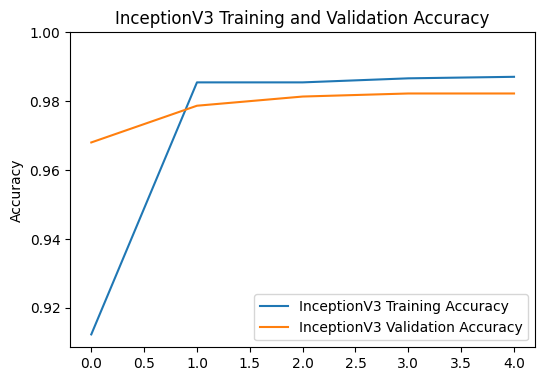

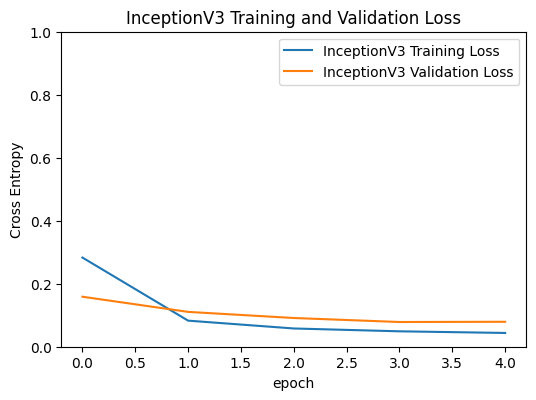

<Figure size 640x480 with 0 Axes>

In [283]:
plt.figure(figsize=(6, 9))
plt.subplot(2, 1, 1)
plt.plot(acc_InceptionV3, label='InceptionV3 Training Accuracy')
plt.plot(val_acc_InceptionV3, label='InceptionV3 Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()),1])
plt.title('InceptionV3 Training and Validation Accuracy')
plt.figure(figsize=(6, 9))
plt.subplot(2, 1, 2)
plt.plot(loss_InceptionV3, label='InceptionV3 Training Loss')
plt.plot(val_loss_InceptionV3, label='InceptionV3 Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.ylim([0,1.0])
plt.title('InceptionV3 Training and Validation Loss')
plt.xlabel('epoch')

plt.savefig('InceptionV3_Full.pdf', format='pdf')
plt.savefig('InceptionV3_Full.png', format='png')
plt.show()

plt.savefig('InceptionV3_Full.pdf', format='pdf', dpi=300)
plt.savefig('InceptionV3_Full.svg', format='svg')
plt.savefig('InceptionV3_Full.png', format='png', dpi=300)
plt.show()

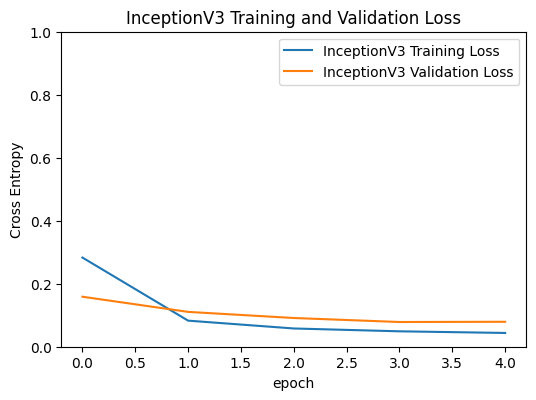

<Figure size 640x480 with 0 Axes>

In [284]:
plt.figure(figsize=(6, 9))
plt.subplot(2, 1, 2)
plt.plot(loss_InceptionV3, label='InceptionV3 Training Loss')
plt.plot(val_loss_InceptionV3, label='InceptionV3 Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.ylim([0,1.0])
plt.title('InceptionV3 Training and Validation Loss')
plt.xlabel('epoch')
plt.savefig('InceptionV3_loss.pdf', format='pdf')
plt.savefig('InceptionV3_loss.png', format='png')
plt.show()

plt.savefig('InceptionV3_loss.pdf', format='pdf', dpi=300)
plt.savefig('InceptionV3_loss.svg', format='svg')
plt.savefig('InceptionV3_loss.png', format='png', dpi=300)
plt.show()

## Test_ds (InceptionV3)

Predictions:
 [0 1 0 0 0 0 1 0 1 0 1 1 0 0 1 0 0 1 0 0 0 0 0 0 1 0 0 1 0 1 1 0 1 0 1 1 1
 0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 1 0 0 0 0 1 0 0 1 1 1 1 1 0 1 0 0 1 1
 0 0 1 1 0 0 0 1 0 0 0 1 0 1 1 0 1 1 1 1 1 1 0 0 0 0 0 0 0 0 1 0 1 0 1 0 0
 0 0 1 0 0 1 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 1 1 1 0 0 0 1 0 0
 0 0 0 1 0 1 1 1 0 0 0 0 1 0 1 0 1 0 0 1 0 0 0 1 1 1 0 1 1 1 1 0 1 0 1 1 0
 0 0 0 1 0 1 0 0 1 1 1 1 0 1 0 0 1 1 0 0 0 1 1 1 1 1 1 0 0 1 0 0 0 0 0 0 1
 0 0 1 0 1 0 0 1 0 0 0 0 0 0 1 1 0 1 1 0 0 0 0 0 0 0 1 0 0 1 0 0 0 1 1 1 0
 0 1 1 0 0 0 0 0 0 0 1 1 0 1 1 0 1 0 1 0 0 0 1 0 0 1 1 0 0 0 0 1 0 1 0 0 1
 0 1 1 0 0 1 0 1 0 1 0 0 0 0 0 1 1 1 0 1 0 0 1 0 0 1 0 1 0 1 0 0 0 1 0 0 1
 0 0 0 1 1 0 1 0 1 1 0 0 0 1 0 1 0 1 0 1 0 0 0 0 1 0 0 0 0 0 1 0 1 0 0 0 1
 0 1 0 0 0 0 0 1 0 0 1 1 1 0 1 1 1 1 0 1 0 0 0 1 1 1 0 0 0 1 0 0 1 0 1 0 0
 1 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 1 1 1 0 1 1 0 0 1 1 0 1 0 1 0 1 1 0 0 1 0
 0 0 1 1 0 0 0 1 0 0 0 1 0 1 0 1 1 0 1 0 1 0 1 0 1 0 0 0 0 1 1 0 1 1 1 1 0
 1 0 0 0 1 

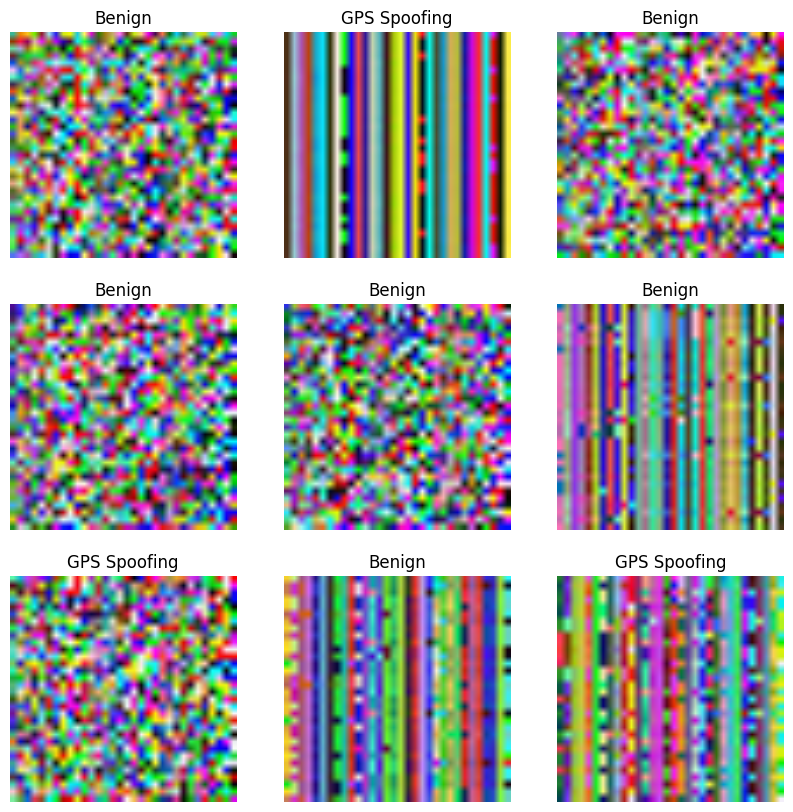

In [285]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_InceptionV3 = []
all_labels_InceptionV3 = []

for image_batch, label_batch in test_ds.as_numpy_iterator():
    predictions = model_InceptionV3.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_InceptionV3.append(predictions)
    all_labels_InceptionV3.append(label_batch)
    
all_predictions_InceptionV3 = np.concatenate(all_predictions_InceptionV3)
all_labels_InceptionV3 = np.concatenate(all_labels_InceptionV3)
print('Predictions:\n', all_predictions_InceptionV3)
print('Labels:\n', all_labels_InceptionV3)

report_InceptionV3 = classification_report(all_labels_InceptionV3, all_predictions_InceptionV3, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_InceptionV3[i]])
    plt.axis("off")

In [286]:
cm=confusion_matrix(all_labels_InceptionV3 ,all_predictions_InceptionV3)
TP = np.sum((all_predictions_InceptionV3 == 1) & (all_labels_InceptionV3 == 1))
FP = np.sum((all_predictions_InceptionV3 == 1) & (all_labels_InceptionV3 == 0))
FN = np.sum((all_predictions_InceptionV3 == 0) & (all_labels_InceptionV3 == 1))
TN = cm[0, 0]
DA = (TP + TN) / len(all_labels_InceptionV3)
DP = TP / (TP + FP)
DS = TP / (TP + FN)
DF = 2 * (DP * DS) / (DP + DS)
DE = 1 - DA
FR = FP / (FP + TN)
total_predictions = TP + FP + TN + FN
prediction_overhead = (TP + FP) / total_predictions
TN, FP, FN, TP = confusion_matrix(all_labels_InceptionV3, all_predictions_InceptionV3).ravel()
specificity = TN / (TN + FP)

test_ds (InceptionV3)
                  
              precision    recall  f1-score   support

      Benign       0.98      1.00      0.99       327
GPS Spoofing       1.00      0.97      0.99       249

    accuracy                           0.99       576
   macro avg       0.99      0.99      0.99       576
weighted avg       0.99      0.99      0.99       576

                  
1) Accuracy: 0.9878472222222222
                  
2) Precision: 0.9881019211576846
                  
3) Recall: 0.9878472222222222
                  
4) Average F1-score: 0.9878249425103193
                  
5) F1-score for each type of attack: [0.98940998 0.98574338]
                  
6) Average ROC AUC: 0.9859437751004017
                  
7) Average PR AUC: 0.984040327978581
                  
8) Balanced Accuracy: 0.9859437751004017
                  
9) Hinge: 0.5798611111111112
                  
10) Matthews Correlation Coefficient: 0.9754581741151652
                  
11) Jaccard Score: 0.971

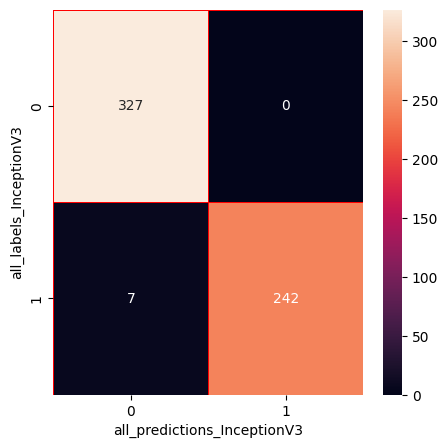

In [287]:
print("test_ds (InceptionV3)")
print("                  ")
print(report_InceptionV3)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_InceptionV3 , all_predictions_InceptionV3)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_InceptionV3, all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_InceptionV3, all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_InceptionV3 ,all_predictions_InceptionV3)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_InceptionV3")
plt.ylabel("all_labels_InceptionV3")
plt.show()

In [288]:
loss_test_InceptionV3, accuracy_test_InceptionV3 = model_InceptionV3.evaluate(test_ds) 
print("Test Loss: {:.4f}".format(loss_test_InceptionV3))
print("Test Accuracy: {:.4f}".format(accuracy_test_InceptionV3))

18/18 [==============================] - 1s 31ms/step - loss: 0.0561 - accuracy: 0.9896
Test Loss: 0.0561
Test Accuracy: 0.9896


In [289]:
saved_info = {
    'class_names': class_names,
    'all_labels_InceptionV3': all_labels_InceptionV3,
    'all_predictions_InceptionV3': all_predictions_InceptionV3,
    'cm': cm,
    'accuracy_score': accuracy_score(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'precision_score': precision_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'recall_score': recall_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'f1_score_weighted': f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'f1_score_each': f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Hinge': hinge_loss(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Jaccard Score': jaccard_score(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Log Loss': log_loss(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Zero-One Loss': zero_one_loss(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('InceptionV3_test_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [290]:
with open('InceptionV3_test_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)

print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_labels_InceptionV3'])
print("  ")
print("predictions:", saved_info['all_predictions_InceptionV3'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [0 1 0 0 0 0 1 1 1 0 1 1 0 0 1 0 0 1 0 0 0 0 0 0 1 0 0 1 0 1 1 0 1 0 1 1 1
 0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 1 0 0 0 0 1 0 0 1 1 1 1 1 0 1 0 0 1 1
 1 0 1 1 0 0 0 1 0 0 0 1 0 1 1 0 1 1 1 1 1 1 0 0 0 0 0 0 0 0 1 0 1 0 1 0 0
 0 0 1 0 0 1 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 1 1 1 0 0 0 1 0 0
 0 1 0 1 0 1 1 1 0 0 0 0 1 0 1 0 1 0 0 1 0 0 0 1 1 1 0 1 1 1 1 0 1 0 1 1 0
 0 0 0 1 0 1 0 1 1 1 1 1 0 1 0 0 1 1 0 0 0 1 1 1 1 1 1 0 0 1 0 0 0 0 0 0 1
 0 0 1 0 1 1 0 1 0 0 0 0 0 0 1 1 0 1 1 0 0 0 0 0 0 0 1 0 0 1 0 0 0 1 1 1 0
 0 1 1 0 0 0 0 0 0 0 1 1 0 1 1 0 1 0 1 0 0 0 1 0 0 1 1 0 0 0 0 1 0 1 0 0 1
 0 1 1 0 0 1 0 1 0 1 0 0 0 0 0 1 1 1 0 1 0 0 1 0 0 1 0 1 0 1 0 0 0 1 0 0 1
 0 0 0 1 1 0 1 0 1 1 0 0 0 1 0 1 0 1 0 1 0 0 0 0 1 0 0 0 0 0 1 0 1 0 0 0 1
 0 1 0 0 0 0 0 1 0 0 1 1 1 0 1 1 1 1 0 1 0 0 0 1 1 1 0 0 0 1 0 0 1 0 1 0 0
 1 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 1 1 1 0 1 1 0 0 1 1 0 1 0 1 0 1 1 0 0 1 0
 0 0 1 1 0 1 0 1 0 0 0 1 0 1 0 1 1 0 1 0 1 0 1 0 1 0 0 0 0 1 1 0 1

## Val_ds (InceptionV3)

Predictions:
 [1 1 1 ... 1 1 0]
Labels:
 [1 1 1 ... 1 1 0]


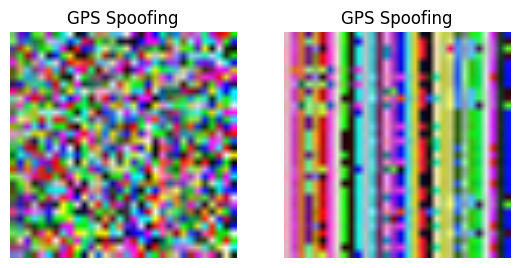

In [291]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_InceptionV3 = []
all_labels_InceptionV3 = []

for image_batch, label_batch in val_ds.as_numpy_iterator():
    predictions = model_InceptionV3.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_InceptionV3.append(predictions)
    all_labels_InceptionV3.append(label_batch)

all_predictions_InceptionV3 = np.concatenate(all_predictions_InceptionV3)
all_labels_InceptionV3 = np.concatenate(all_labels_InceptionV3)
print('Predictions:\n', all_predictions_InceptionV3)
print('Labels:\n', all_labels_InceptionV3)
report_InceptionV3 = classification_report(all_labels_InceptionV3, all_predictions_InceptionV3, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(2):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_InceptionV3[i]])
    plt.axis("off")

val_ds (InceptionV3)
                  
              precision    recall  f1-score   support

      Benign       0.97      1.00      0.99       633
GPS Spoofing       1.00      0.97      0.98       493

    accuracy                           0.98      1126
   macro avg       0.99      0.98      0.98      1126
weighted avg       0.99      0.98      0.98      1126

                  
1) Accuracy: 0.9849023090586145
                  
2) Precision: 0.9852971717447737
                  
3) Recall: 0.9849023090586145
                  
4) Average F1-score: 0.9848698968465869
                  
5) F1-score for each type of attack: [0.98674981 0.98245614]
                  
6) Average ROC AUC: 0.9827586206896552
                  
7) Average PR AUC: 0.9806149323206959
                  
8) Balanced Accuracy: 0.9827586206896552
                  
9) Hinge: 0.5772646536412078
                  
10) Matthews Correlation Coefficient: 0.9696727551031791
                  
11) Jaccard Score: 0.965

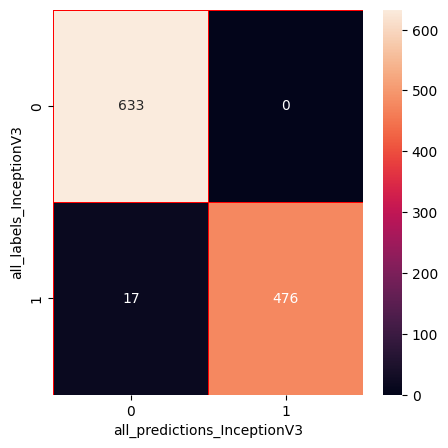

In [292]:
print("val_ds (InceptionV3)")
print("                  ")
print(report_InceptionV3)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_InceptionV3 , all_predictions_InceptionV3)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_InceptionV3, all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_InceptionV3, all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_InceptionV3 ,all_predictions_InceptionV3)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_InceptionV3")
plt.ylabel("all_labels_InceptionV3")
plt.show()

In [293]:
loss_val_InceptionV3, accuracy_val_InceptionV3 = model_InceptionV3.evaluate(val_ds) 
print("Validation Loss: {:.4f}".format(loss_val_InceptionV3))
print("Validation Accuracy: {:.4f}".format(accuracy_val_InceptionV3))

36/36 [==============================] - 1s 30ms/step - loss: 0.0734 - accuracy: 0.9840
Validation Loss: 0.0734
Validation Accuracy: 0.9840


In [294]:
saved_info = {
    'class_names': class_names,
    'all_labels_InceptionV3': all_labels_InceptionV3,
    'all_predictions_InceptionV3': all_predictions_InceptionV3,
    'cm': cm,
    'accuracy_score': accuracy_score(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'precision_score': precision_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'recall_score': recall_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'f1_score_weighted': f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'f1_score_each': f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Hinge': hinge_loss(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Jaccard Score': jaccard_score(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Log Loss': log_loss(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Zero-One Loss': zero_one_loss(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('InceptionV3_val_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [295]:
with open('InceptionV3_val_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)

print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_labels_InceptionV3'])
print("  ")
print("predictions:", saved_info['all_predictions_InceptionV3'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [1 1 1 ... 1 1 0]
  
predictions: [1 1 1 ... 1 1 0]
  
cm: [[633   0]
 [ 17 476]]
  
1) Accuracy: 0.9849023090586145
  
2) Precision: 0.9852971717447737
  
3) Recall: 0.9849023090586145
  
4) Average F1-score: 0.9848698968465869
  
5) F1-score for each type of attack: [0.98674981 0.98245614]
  
6) Average ROC AUC: 0.9827586206896552
  
7) Average PR AUC: 0.9806149323206959
  
8) Balanced Accuracy: 1.0
  
9) Hinge: 0.5772646536412078
  
10) Matthews Correlation Coefficient: 0.9696727551031791
  
11) Jaccard Score: 0.9655172413793104
  
12) Log Loss: 0.5441759392673107
  
13) Zero-One Loss: 0.015097690941385467
  
14) Prediction Overhead: 0.4201388888888889
  
15) Specificity: 1.0


## TL + InceptionV3

In [296]:
base_model_InceptionV3.trainable = True
print("Number of layers in the base model: ", len(base_model_InceptionV3.layers))
fine_tune_at_InceptionV3 = int((130/151)*len(base_model_InceptionV3.layers))
for layer in base_model_InceptionV3.layers[:fine_tune_at_InceptionV3]:
  layer.trainable = False
print("frozen layers in the base model from layer 1 to ", fine_tune_at_InceptionV3 )
print("unfrozen layers in the base model from %2d to %3d " % (fine_tune_at_InceptionV3+1,len(base_model_InceptionV3.layers)))

Number of layers in the base model:  311
frozen layers in the base model from layer 1 to  267
unfrozen layers in the base model from 268 to 311 


In [297]:
history= LossHistory()
savepath='./InceptionV3+TL.h5'
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
saveBestModel = kcallbacks.ModelCheckpoint(filepath=savepath, verbose=1, save_best_only=True, mode='auto')
model_InceptionV3.compile(loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              optimizer = tf.keras.optimizers.Adam(learning_rate=0.00005/10),
              metrics=['accuracy'])
model_InceptionV3.summary()
len(model_InceptionV3.trainable_variables)

Model: "model_18"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_38 (InputLayer)       [(None, 224, 224, 3)]     0         
                                                                 
 sequential (Sequential)     (None, 224, 224, 3)       0         
                                                                 
 tf.math.truediv_18 (TFOpLa  (None, 224, 224, 3)       0         
 mbda)                                                           
                                                                 
 tf.math.subtract_18 (TFOpL  (None, 224, 224, 3)       0         
 ambda)                                                          
                                                                 
 inception_v3 (Functional)   (None, 5, 5, 2048)        21802784  
                                                                 
 global_average_pooling2d_8  (None, 2048)              0  

24

In [298]:
%%time
fine_tune_epochs = 5
total_epochs =  initial_epochs + fine_tune_epochs
history_fine_InceptionV3 = model_InceptionV3.fit(train_ds, epochs=total_epochs, initial_epoch=history_InceptionV3.epoch[-1],
                         validation_data=val_ds,
                         callbacks=[early_stop, saveBestModel, history])

# Inference (Detection)
start_time = time.time()
detection_results = model_InceptionV3.predict(val_ds)
end_time = time.time()

detection_time = end_time - start_time

print(f"Detection time: {detection_time} seconds")

Epoch 5/10
213/213 [==============================] - ETA: 0s - loss: 0.0311 - accuracy: 0.9896
Epoch 5: val_loss improved from inf to 0.04553, saving model to ./InceptionV3+TL.h5


/usr/local/lib/python3.9/site-packages/keras/src/engine/training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


213/213 [==============================] - 17s 48ms/step - loss: 0.0311 - accuracy: 0.9896 - val_loss: 0.0455 - val_accuracy: 0.9849
Epoch 6/10
213/213 [==============================] - ETA: 0s - loss: 0.0238 - accuracy: 0.9930
Epoch 6: val_loss did not improve from 0.04553
213/213 [==============================] - 9s 40ms/step - loss: 0.0238 - accuracy: 0.9930 - val_loss: 0.0524 - val_accuracy: 0.9840
Epoch 7/10
213/213 [==============================] - ETA: 0s - loss: 0.0165 - accuracy: 0.9947
Epoch 7: val_loss improved from 0.04553 to 0.03718, saving model to ./InceptionV3+TL.h5
213/213 [==============================] - 9s 43ms/step - loss: 0.0165 - accuracy: 0.9947 - val_loss: 0.0372 - val_accuracy: 0.9849
Epoch 8/10
213/213 [==============================] - ETA: 0s - loss: 0.0132 - accuracy: 0.9959
Epoch 8: val_loss improved from 0.03718 to 0.02719, saving model to ./InceptionV3+TL.h5
213/213 [==============================] - 9s 43ms/step - loss: 0.0132 - accuracy: 0.9959 - 

## InceptionV3 (Learning Curve)

In [299]:
acc_InceptionV3 += history_fine_InceptionV3.history['accuracy']
val_acc_InceptionV3 += history_fine_InceptionV3.history['val_accuracy']
loss_InceptionV3 += history_fine_InceptionV3.history['loss']
val_loss_InceptionV3 += history_fine_InceptionV3.history['val_loss']

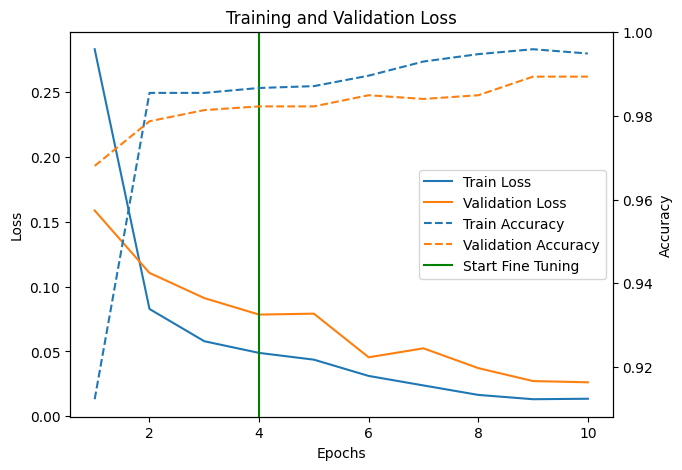

In [301]:
actual_epochs = range(1, total_epochs + 1)
actual_train_loss = loss_InceptionV3[:total_epochs]  
actual_val_loss = val_loss_InceptionV3[:total_epochs]  
actual_train_accuracy = acc_InceptionV3[:total_epochs]  
actual_val_accuracy = val_acc_InceptionV3[:total_epochs]

fig, ax1 = plt.subplots(figsize=(7, 5))
ax1.plot(actual_epochs, actual_train_loss, '-', label='Train Loss')
ax1.plot(actual_epochs, actual_val_loss, '-', label='Validation Loss')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.set_title('Training and Validation Loss')

ax2 = ax1.twinx()
ax2.plot(actual_epochs, actual_train_accuracy, '--', label='Train Accuracy')
ax2.plot(actual_epochs, actual_val_accuracy, '--', label='Validation Accuracy')
ax2.set_ylabel('Accuracy')
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
custom_legend_elements = handles1 + handles2 + [plt.Line2D([0], [0], color='green', label='Start Fine Tuning')]
custom_legend_labels = labels1 + labels2 + ['Start Fine Tuning']
ax1.legend(custom_legend_elements, custom_legend_labels, loc='center right')
ax1.axvline(x=initial_epochs - 1, color='green')
plot_data = {'fig': fig, 'ax1': ax1, 'ax2': ax2}

learning_curve_data = {
    'train_loss': actual_train_loss,
    'val_loss': actual_val_loss,
    'train_acc': actual_train_accuracy,
    'val_acc': actual_val_accuracy
}

with open('InceptionV3+Start Fine Tuning.pkl', 'wb') as file:
    pickle.dump(plot_data, file)
plt.savefig('InceptionV3+Start Fine Tuning.pdf', format='pdf', dpi=300)
plt.savefig('InceptionV3+Start Fine Tuning.svg', format='svg')
plt.savefig('InceptionV3+Start Fine Tuning.png', format='png', dpi=300)
plt.show()

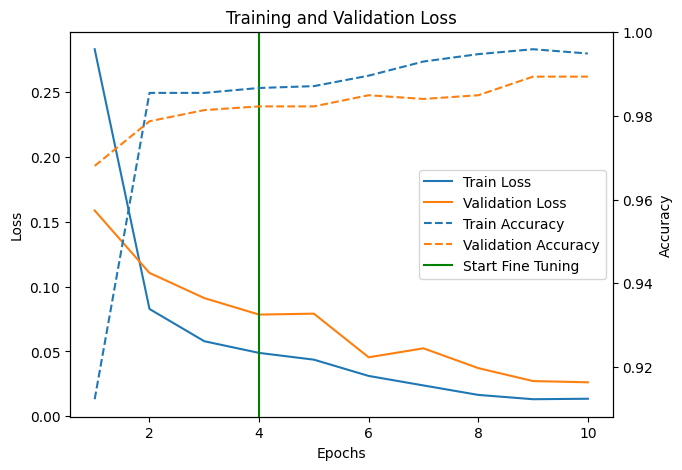

Training Loss: [0.28307780623435974, 0.08278153836727142, 0.05791601166129112, 0.04891049116849899, 0.04370434954762459, 0.031143035739660263, 0.023821020498871803, 0.01652497798204422, 0.013193749822676182, 0.01356398593634367]
Validation Loss: [0.15872728824615479, 0.11060022562742233, 0.09117010235786438, 0.07845880836248398, 0.0791754499077797, 0.045525602996349335, 0.052440062165260315, 0.0371818020939827, 0.027192559093236923, 0.0262474175542593]
Training Accuracy: [0.912321925163269, 0.9854604005813599, 0.9854604005813599, 0.9866353273391724, 0.987075924873352, 0.9895726442337036, 0.9929504990577698, 0.9947128891944885, 0.995887815952301, 0.9948597550392151]
Validation Accuracy: [0.9680284261703491, 0.9786856174468994, 0.9813498854637146, 0.9822379946708679, 0.9822379946708679, 0.9849023222923279, 0.9840142130851746, 0.9849023222923279, 0.9893428087234497, 0.9893428087234497]


In [302]:
with open('InceptionV3+Start Fine Tuning.pkl', 'rb') as file:
    learning_curve = pickle.load(file)
fig = learning_curve['fig']
ax1 = learning_curve['ax1']
ax2 = learning_curve['ax2']
plt.show()

train_loss = learning_curve_data['train_loss']
val_loss = learning_curve_data['val_loss']
train_acc = learning_curve_data['train_acc']
val_acc = learning_curve_data['val_acc']
print("Training Loss:", learning_curve_data['train_loss'])
print("Validation Loss:", learning_curve_data['val_loss'])
print("Training Accuracy:", learning_curve_data['train_acc'])
print("Validation Accuracy:", learning_curve_data['val_acc'])

## Test_ds (InceptionV3) + TL

Predictions:
 [0 0 0 1 1 1 1 0 1 0 0 1 0 1 0 1 0 1 1 1 1 1 1 0 0 0 1 0 1 0 0 0 1 0 1 0 0
 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 1 1 0 0 1 1 0 0 0 1 0 1 1 0 0 0 1 0 0 1 1
 0 0 1 1 1 0 1 0 0 0 0 1 0 0 0 0 1 1 1 0 0 0 1 1 0 1 0 1 1 1 1 1 1 1 1 0 0
 0 0 1 1 0 1 1 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1 1 0 0 0 0 0 0 0 0 0 0
 0 1 0 1 0 1 0 1 0 1 0 0 0 1 1 1 0 1 0 0 0 1 0 1 1 1 1 0 0 1 0 0 0 0 0 0 1
 0 0 0 1 1 0 0 0 0 1 0 0 0 0 0 0 1 0 0 1 0 1 1 0 1 0 1 0 1 1 0 1 0 0 1 1 1
 0 0 1 0 1 0 1 0 0 0 0 0 1 1 0 1 0 0 1 0 0 1 0 0 0 0 1 1 0 0 0 1 0 0 0 0 0
 0 1 1 0 1 0 1 0 1 0 0 0 1 1 1 1 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 1
 0 0 0 0 1 1 0 0 1 0 0 0 0 1 1 1 0 1 1 0 1 0 0 0 1 0 0 1 0 1 1 0 0 1 1 0 1
 1 0 1 0 0 1 1 0 1 1 1 1 1 0 0 0 0 0 1 0 1 1 1 0 1 1 0 1 0 0 1 1 0 1 1 0 0
 0 1 0 0 0 1 1 1 0 1 1 1 0 1 0 0 1 0 0 0 0 1 1 0 0 1 0 0 0 1 1 1 1 0 1 0 1
 0 1 1 1 0 0 0 1 0 0 1 1 1 1 1 1 0 0 0 0 1 0 1 0 0 0 0 1 1 0 0 1 1 0 0 1 1
 1 0 0 1 1 0 0 1 0 0 1 0 1 1 0 0 0 0 0 0 1 0 0 0 1 1 1 1 0 1 1 1 0 0 0 1 0
 1 1 0 0 0 

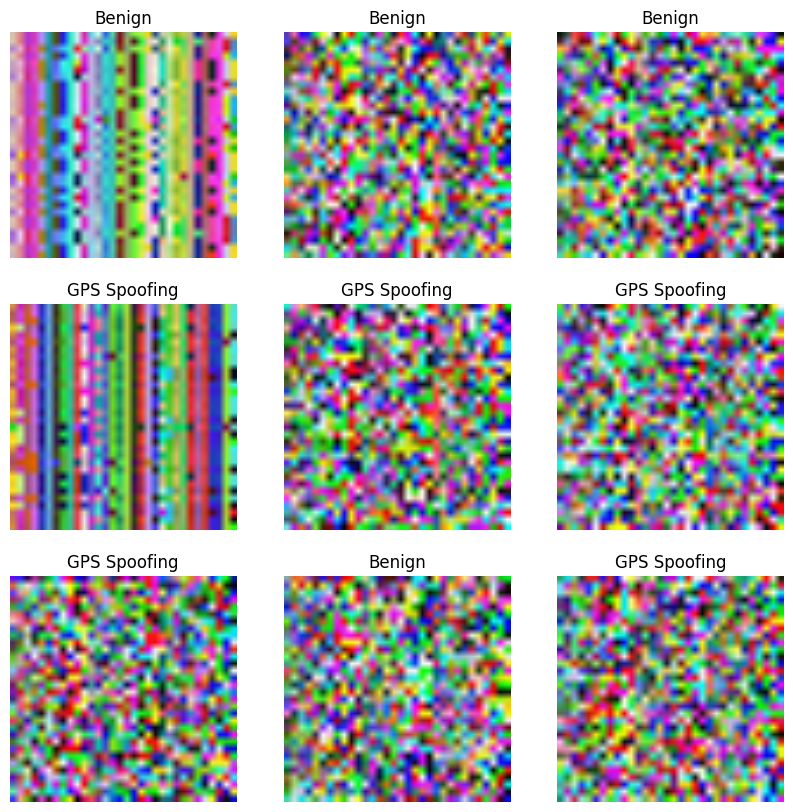

In [303]:
all_predictions_InceptionV3 = []
all_labels_InceptionV3 = []

for image_batch, label_batch in test_ds.as_numpy_iterator():
    predictions = model_InceptionV3.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_InceptionV3.append(predictions)
    all_labels_InceptionV3.append(label_batch)

all_predictions_InceptionV3 = np.concatenate(all_predictions_InceptionV3)
all_labels_InceptionV3 = np.concatenate(all_labels_InceptionV3)
print('Predictions:\n', all_predictions_InceptionV3)
print('Labels:\n', all_labels_InceptionV3)

report_InceptionV3 = classification_report(all_labels_InceptionV3, all_predictions_InceptionV3, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_InceptionV3[i]])
    plt.axis("off")

test_ds (InceptionV3)
                  
              precision    recall  f1-score   support

      Benign       0.99      1.00      1.00       331
GPS Spoofing       1.00      0.99      1.00       245

    accuracy                           1.00       576
   macro avg       1.00      1.00      1.00       576
weighted avg       1.00      1.00      1.00       576

                  
1) Accuracy: 0.9965277777777778
                  
2) Precision: 0.9965486319652987
                  
3) Recall: 0.9965277777777778
                  
4) Average F1-score: 0.9965258918186408
                  
5) F1-score for each type of attack: [0.99698795 0.99590164]
                  
6) Average ROC AUC: 0.9959183673469387
                  
7) Average PR AUC: 0.9953089569160998
                  
8) Balanced Accuracy: 0.9959183673469387
                  
9) Hinge: 0.578125
                  
10) Matthews Correlation Coefficient: 0.9929147784721148
                  
11) Jaccard Score: 0.991836734693

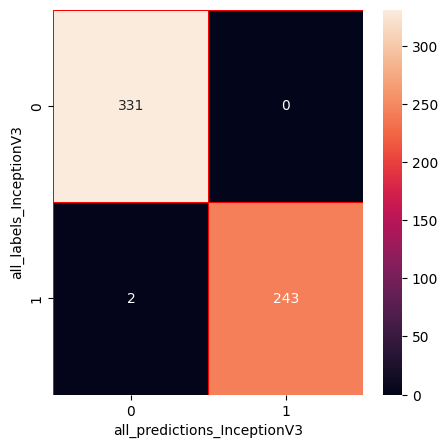

In [304]:
print("test_ds (InceptionV3)")
print("                  ")
print(report_InceptionV3)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_InceptionV3 , all_predictions_InceptionV3)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_InceptionV3, all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_InceptionV3, all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_InceptionV3 ,all_predictions_InceptionV3)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_InceptionV3")
plt.ylabel("all_labels_InceptionV3")
plt.show()

In [305]:
loss_test_InceptionV3, accuracy_test_InceptionV3 = model_InceptionV3.evaluate(test_ds)
print("Test loss: {:.4f}".format(loss_test_InceptionV3))
print("Test accuracy: {:.4f}".format(accuracy_test_InceptionV3))

18/18 [==============================] - 1s 31ms/step - loss: 0.0107 - accuracy: 0.9948
Test loss: 0.0107
Test accuracy: 0.9948


In [306]:
saved_info = {
    'class_names': class_names,
    'all_labels_InceptionV3': all_labels_InceptionV3,
    'all_predictions_InceptionV3': all_predictions_InceptionV3,
    'cm': cm,
    'accuracy_score': accuracy_score(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'precision_score': precision_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'recall_score': recall_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'f1_score_weighted': f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'f1_score_each': f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Hinge': hinge_loss(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Jaccard Score': jaccard_score(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Log Loss': log_loss(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Zero-One Loss': zero_one_loss(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('InceptionV3_test(TL)_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [307]:
with open('InceptionV3_test(TL)_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)

print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_labels_InceptionV3'])
print("  ")
print("predictions:", saved_info['all_predictions_InceptionV3'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [0 0 0 1 1 1 1 0 1 0 0 1 0 1 0 1 1 1 1 1 1 1 1 0 0 0 1 0 1 0 0 0 1 0 1 0 0
 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 1 1 0 0 1 1 0 0 0 1 0 1 1 0 0 0 1 0 0 1 1
 0 0 1 1 1 0 1 0 0 0 0 1 0 0 0 0 1 1 1 0 0 0 1 1 0 1 0 1 1 1 1 1 1 1 1 0 0
 0 0 1 1 0 1 1 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1 1 0 0 0 0 0 0 0 0 0 0
 0 1 0 1 0 1 0 1 0 1 0 0 0 1 1 1 0 1 0 0 0 1 0 1 1 1 1 0 0 1 1 0 0 0 0 0 1
 0 0 0 1 1 0 0 0 0 1 0 0 0 0 0 0 1 0 0 1 0 1 1 0 1 0 1 0 1 1 0 1 0 0 1 1 1
 0 0 1 0 1 0 1 0 0 0 0 0 1 1 0 1 0 0 1 0 0 1 0 0 0 0 1 1 0 0 0 1 0 0 0 0 0
 0 1 1 0 1 0 1 0 1 0 0 0 1 1 1 1 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 1
 0 0 0 0 1 1 0 0 1 0 0 0 0 1 1 1 0 1 1 0 1 0 0 0 1 0 0 1 0 1 1 0 0 1 1 0 1
 1 0 1 0 0 1 1 0 1 1 1 1 1 0 0 0 0 0 1 0 1 1 1 0 1 1 0 1 0 0 1 1 0 1 1 0 0
 0 1 0 0 0 1 1 1 0 1 1 1 0 1 0 0 1 0 0 0 0 1 1 0 0 1 0 0 0 1 1 1 1 0 1 0 1
 0 1 1 1 0 0 0 1 0 0 1 1 1 1 1 1 0 0 0 0 1 0 1 0 0 0 0 1 1 0 0 1 1 0 0 1 1
 1 0 0 1 1 0 0 1 0 0 1 0 1 1 0 0 0 0 0 0 1 0 0 0 1 1 1 1 0 1 1 1 0

## Val_ds + (InceptionV3) + TL

Predictions:
 [1 1 1 ... 0 0 1]
Labels:
 [1 1 1 ... 0 0 1]


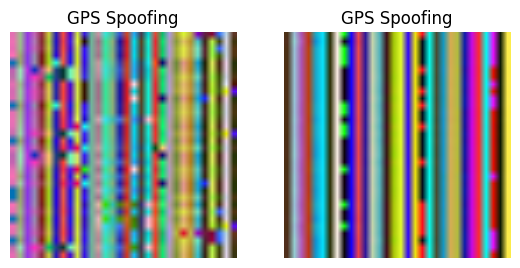

In [308]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_InceptionV3 = []
all_labels_InceptionV3 = []

for image_batch, label_batch in val_ds.as_numpy_iterator():
    predictions = model_InceptionV3.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_InceptionV3.append(predictions)
    all_labels_InceptionV3.append(label_batch)

all_predictions_InceptionV3 = np.concatenate(all_predictions_InceptionV3)
all_labels_InceptionV3 = np.concatenate(all_labels_InceptionV3)
print('Predictions:\n', all_predictions_InceptionV3)
print('Labels:\n', all_labels_InceptionV3)

report_InceptionV3 = classification_report(all_labels_InceptionV3, all_predictions_InceptionV3, target_names=class_names_s)

plt.figure(figsize=(10, 10))
for i in range(2):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_InceptionV3[i]])
    plt.axis("off")

val_ds (InceptionV3)
                  
              precision    recall  f1-score   support

      Benign       0.98      1.00      0.99       639
GPS Spoofing       1.00      0.98      0.99       487

    accuracy                           0.99      1126
   macro avg       0.99      0.99      0.99      1126
weighted avg       0.99      0.99      0.99      1126

                  
1) Accuracy: 0.9911190053285968
                  
2) Precision: 0.991255846540791
                  
3) Recall: 0.9911190053285968
                  
4) Average F1-score: 0.9911074179892179
                  
5) F1-score for each type of attack: [0.99223602 0.98962656]
                  
6) Average ROC AUC: 0.9897330595482546
                  
7) Average PR AUC: 0.9883471137679124
                  
8) Balanced Accuracy: 0.9897330595482546
                  
9) Hinge: 0.5763765541740675
                  
10) Matthews Correlation Coefficient: 0.9820255552791742
                  
11) Jaccard Score: 0.9794

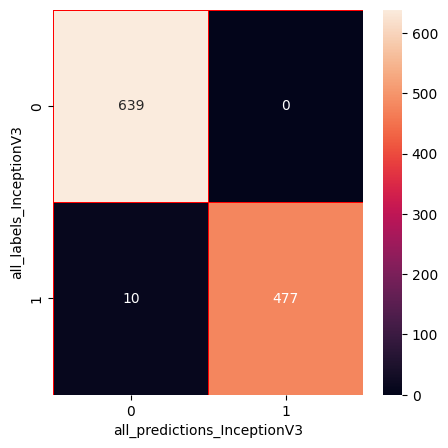

In [309]:
print("val_ds (InceptionV3)")
print("                  ")
print(report_InceptionV3)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_InceptionV3 , all_predictions_InceptionV3)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_InceptionV3, all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_InceptionV3, all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_InceptionV3 ,all_predictions_InceptionV3)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_InceptionV3")
plt.ylabel("all_labels_InceptionV3")
plt.show()

In [310]:
loss_val_InceptionV3, accuracy_val_InceptionV3 = model_InceptionV3.evaluate(val_ds)
print("Validation Loss: {:.4f}".format(loss_val_InceptionV3))
print("Validation Accuracy: {:.4f}".format(accuracy_val_InceptionV3))

36/36 [==============================] - 1s 30ms/step - loss: 0.0187 - accuracy: 0.9911
Validation Loss: 0.0187
Validation Accuracy: 0.9911


In [311]:
saved_info = {
    'class_names': class_names,
    'all_labels_InceptionV3': all_labels_InceptionV3,
    'all_predictions_InceptionV3': all_predictions_InceptionV3,
    'cm': cm,
    'accuracy_score': accuracy_score(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'precision_score': precision_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'recall_score': recall_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'f1_score_weighted': f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'f1_score_each': f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Hinge': hinge_loss(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Jaccard Score': jaccard_score(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Log Loss': log_loss(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Zero-One Loss': zero_one_loss(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('InceptionV3_val(TL)_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [312]:
with open('InceptionV3_val(TL)_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)

print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_labels_InceptionV3'])
print("  ")
print("predictions:", saved_info['all_predictions_InceptionV3'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [1 1 1 ... 0 0 1]
  
predictions: [1 1 1 ... 0 0 1]
  
cm: [[639   0]
 [ 10 477]]
  
1) Accuracy: 0.9911190053285968
  
2) Precision: 0.991255846540791
  
3) Recall: 0.9911190053285968
  
4) Average F1-score: 0.9911074179892179
  
5) F1-score for each type of attack: [0.99223602 0.98962656]
  
6) Average ROC AUC: 0.9897330595482546
  
7) Average PR AUC: 0.9883471137679124
  
8) Balanced Accuracy: 1.0
  
9) Hinge: 0.5763765541740675
  
10) Matthews Correlation Coefficient: 0.9820255552791742
  
11) Jaccard Score: 0.9794661190965093
  
12) Log Loss: 0.3201034936866534
  
13) Zero-One Loss: 0.008880994671403242
  
14) Prediction Overhead: 0.4201388888888889
  
15) Specificity: 1.0


## Load the saved model and learning curve

In [314]:
new_model = tf.keras.models.load_model('./InceptionV3+TL.h5')

In [315]:
for layer in new_model.layers:
    print(layer.name)
    weights = layer.get_weights()
    for weight in weights:
        print(weight)

input_38
sequential
tf.math.truediv_18
tf.math.subtract_18
inception_v3
[[[[-4.59105551e-01 -4.14526574e-02 -3.62577499e-03 -9.87672508e-02
    -3.37070860e-02  4.79929037e-02  2.32542142e-01  3.23927671e-01
     5.90160079e-02  9.47738215e-02  4.24996056e-02  1.26620471e-01
     1.33215979e-01  1.22741833e-01 -7.92686343e-02  2.08227970e-02
    -1.99647829e-01 -3.02687973e-01 -2.10659921e-01 -3.52898419e-01
    -5.58023095e-01  3.20223093e-01  4.53596050e-03 -3.09266411e-02
    -6.86957911e-02  2.00968519e-01  1.14542745e-01  2.40372881e-01
     1.52943470e-02  5.96231259e-02 -5.85714653e-02  8.78173351e-01]
   [ 3.16376328e-01 -4.78494260e-03 -6.84681814e-03  7.44503662e-02
    -1.97458476e-01  5.20143658e-02 -1.24460436e-01  3.36123914e-01
     3.01678218e-02 -1.26477107e-01 -1.05597451e-01 -5.31241074e-02
    -2.43102223e-01  1.66047230e-01 -1.03186309e-01 -6.55613691e-02
     2.60930099e-02  1.16658449e-01 -1.60814777e-01 -3.49688202e-01
    -7.33594477e-01  3.11471581e-01  1.3300

In [316]:
print(new_model.get_config())

{'name': 'model_18', 'trainable': True, 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_input_shape': (None, 224, 224, 3), 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'input_38'}, 'registered_name': None, 'name': 'input_38', 'inbound_nodes': []}, {'module': 'keras', 'class_name': 'Sequential', 'config': {'name': 'sequential', 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_input_shape': (None, 224, 224, 3), 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'random_flip_input'}, 'registered_name': None}, {'module': 'keras.layers', 'class_name': 'RandomFlip', 'config': {'name': 'random_flip', 'trainable': True, 'dtype': 'float32', 'mode': 'horizontal_and_vertical', 'seed': None}, 'registered_name': None, 'build_config': {'input_shape': (None, 224, 224, 3)}}, {'module': 'keras.layers', 'class_name': 'RandomRotation', 'config': {'name': 'random_rotation', 'trainable': True, 'dtype': 'float

# Hyperparameter optimization using Bayesian optimization with tree-based Parzen estimator (BO-TPE) for InceptionV3

In [250]:
fine_tune_epochs = 4

In [251]:
total_epochs =  initial_epochs + fine_tune_epochs

In [26]:
from hyperopt import fmin, tpe, hp, STATUS_OK, Trials
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping
import hyperopt

# Define the search space
space = {
    'frozen': hp.quniform('frozen', 1, 780, 50),
    'epochs': hp.quniform('epochs', 1, 20, 1),
    'patience': hp.quniform('patience', 2, 5, 1),
    'lr': hp.quniform('lr', 0.00003, 0.00009, 0.00001),
    'dropout_rate': hp.quniform('dropout_rate', 0.2, 0.5, 0.1),
    'weight_decay': hp.uniform('weight_decay', 1e-9, 1e-3),
    'learning_rate_schedule': hp.choice('learning_rate_schedule', ['constant', 'exponential', 'step_decay']),
    'optimizer': hp.choice('optimizer', ['adam', 'rmsprop', 'sgd'])
}

# Function to optimize
def objective(params):
    # Convert frozen layers count to integer
    frozen_layers = int(params['frozen'])
    
    # Create a new instance of the base model
    base_model_InceptionV3 = tf.keras.applications.InceptionV3(
        input_shape=IMG_SHAPE,
        include_top=False,
        weights='imagenet')

    # Freeze specified layers
    for layer in base_model_InceptionV3.layers[:frozen_layers]:
        layer.trainable = False

    # Build the model
    inputs_InceptionV3 = tf.keras.Input(shape=(img_height, img_width, 3))
    x_InceptionV3 = data_augmentation(inputs_InceptionV3)
    x_InceptionV3 = tf.keras.applications.inception_resnet_v2.preprocess_input(x_InceptionV3)
    x_InceptionV3 = base_model_InceptionV3(x_InceptionV3, training=False)
    x_InceptionV3 = global_average_layer(x_InceptionV3)
    x_InceptionV32 = tf.keras.layers.Dropout(params['dropout_rate'])(x_InceptionV3)
    outputs_InceptionV3 = prediction_layer_InceptionV3(x_InceptionV3)
    model_InceptionV3 = tf.keras.Model(inputs_InceptionV3, outputs_InceptionV3)

    # Compile the model
    if params['optimizer'] == 'adam':
        optimizer = tf.keras.optimizers.Adam(learning_rate=params['lr'], weight_decay=params['weight_decay'])
    elif params['optimizer'] == 'rmsprop':
        optimizer = tf.keras.optimizers.RMSprop(learning_rate=params['lr'], weight_decay=params['weight_decay'])
    elif params['optimizer'] == 'sgd':
        optimizer = tf.keras.optimizers.SGD(learning_rate=params['lr'], weight_decay=params['weight_decay'])

    model_InceptionV3.compile(
        optimizer=optimizer,
        loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
        metrics=['accuracy']
    )

    # Train the model
    history_InceptionV3 = model_InceptionV3.fit(
        train_ds,
        epochs=int(params['epochs']),
        validation_data=val_ds,
        callbacks=[EarlyStopping(monitor='val_loss', patience=int(params['patience']))],
        verbose=0
    )

    # Get the best validation accuracy
    best_val_acc = max(history_InceptionV3.history['val_accuracy'])

    return {'loss': -best_val_acc, 'status': STATUS_OK}

# Create Trials object to keep track of the optimization process
trials = Trials()

# Perform Bayesian optimization with TPE
best = fmin(
    fn=objective,
    space=space,
    algo=tpe.suggest,
    max_evals=20,  # Adjust the number of evaluations as needed
    trials=trials
)

print("Best Hyperparameters:", best)

  0%|          | 0/20 [00:00<?, ?trial/s, best loss=?]

2024-02-08 15:51:23.766470: I tensorflow/compiler/xla/service/service.cc:168] XLA service 0x561ae496da50 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2024-02-08 15:51:23.766489: I tensorflow/compiler/xla/service/service.cc:176]   StreamExecutor device (0): Tesla V100-SXM2-32GB, Compute Capability 7.0
2024-02-08 15:51:23.834379: I ./tensorflow/compiler/jit/device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


 15%|█▌        | 3/20 [03:51<20:40, 72.98s/trial, best loss: -0.9769093990325928]

2024-02-08 15:55:14.636782: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


100%|██████████| 20/20 [36:24<00:00, 109.20s/trial, best loss: -1.0]             
Best Hyperparameters: {'dropout_rate': 0.4, 'epochs': 7.0, 'frozen': 50.0, 'learning_rate_schedule': 0, 'lr': 8e-05, 'optimizer': 0, 'patience': 4.0, 'weight_decay': 0.0005578060854477372}


In [252]:
# Extract the best hyperparameters from the optimization result
best_hyperparameters = {
    'dropout_rate': 0.4,
    'epochs': 7,
    'frozen': 50,
    'learning_rate_schedule': 0,
    'lr': 8e-05,
    'optimizer': 0,
    'patience': 4,
    'weight_decay': 0.0005578060854477372
}

# Convert frozen layers count to integer
frozen_layers = int(best_hyperparameters['frozen'])

# Create a new instance of the base model
base_model_InceptionV3 = tf.keras.applications.InceptionV3(
    input_shape=IMG_SHAPE,
    include_top=False,
    weights='imagenet')

# Freeze specified layers
for layer in base_model_InceptionV3.layers[:frozen_layers]:
    layer.trainable = False

# Build the model
inputs_InceptionV3 = tf.keras.Input(shape=(img_height, img_width, 3))
x_InceptionV3 = data_augmentation(inputs_InceptionV3)
x_InceptionV3 = tf.keras.applications.inception_v3.preprocess_input(x_InceptionV3)
x_InceptionV3 = base_model_InceptionV3(x_InceptionV3, training=False)
x_InceptionV3 = global_average_layer(x_InceptionV3)
x_InceptionV3 = tf.keras.layers.Dropout(best_hyperparameters['dropout_rate'])(x_InceptionV3)
outputs_InceptionV3 = prediction_layer_InceptionV3(x_InceptionV3)
model_InceptionV3 = tf.keras.Model(inputs_InceptionV3, outputs_InceptionV3)

# Compile the model
if best_hyperparameters['optimizer'] == 0:
    optimizer = tf.keras.optimizers.Adam(learning_rate=best_hyperparameters['lr'], weight_decay=best_hyperparameters['weight_decay'])
elif best_hyperparameters['optimizer'] == 1:
    optimizer = tf.keras.optimizers.RMSprop(learning_rate=best_hyperparameters['lr'], weight_decay=best_hyperparameters['weight_decay'])
elif best_hyperparameters['optimizer'] == 2:
    optimizer = tf.keras.optimizers.SGD(learning_rate=best_hyperparameters['lr'], weight_decay=best_hyperparameters['weight_decay'])

model_InceptionV3.compile(
    optimizer=optimizer,
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=['accuracy']
)

# Fine-tuning
history_fine_InceptionV3 = model_InceptionV3.fit(
    train_ds,
    epochs=total_epochs,
    initial_epoch=history_InceptionV3.epoch[-1],
    validation_data=val_ds,
    callbacks=[early_stop, saveBestModel, history]
)

# Inference (Detection)
start_time = time.time()
detection_results = model_InceptionV3.predict(val_ds)
end_time = time.time()

detection_time = end_time - start_time

print(f"Detection time: {detection_time} seconds")


Epoch 3/7
213/213 [==============================] - ETA: 0s - loss: 0.0716 - accuracy: 0.9819
Epoch 3: val_loss improved from inf to 0.03953, saving model to ./InceptionV3+TL.h5


/usr/local/lib/python3.9/site-packages/keras/src/engine/training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


213/213 [==============================] - 38s 91ms/step - loss: 0.0716 - accuracy: 0.9819 - val_loss: 0.0395 - val_accuracy: 0.9840
Epoch 4/7
213/213 [==============================] - ETA: 0s - loss: 0.0244 - accuracy: 0.9940
Epoch 4: val_loss improved from 0.03953 to 0.00018, saving model to ./InceptionV3+TL.h5
213/213 [==============================] - 18s 87ms/step - loss: 0.0244 - accuracy: 0.9940 - val_loss: 1.8376e-04 - val_accuracy: 1.0000
Epoch 5/7
213/213 [==============================] - ETA: 0s - loss: 0.0101 - accuracy: 0.9977
Epoch 5: val_loss did not improve from 0.00018
213/213 [==============================] - 17s 82ms/step - loss: 0.0101 - accuracy: 0.9977 - val_loss: 5.3636e-04 - val_accuracy: 1.0000
Epoch 6/7
213/213 [==============================] - ETA: 0s - loss: 6.3444e-04 - accuracy: 0.9996
Epoch 6: val_loss improved from 0.00018 to 0.00004, saving model to ./InceptionV3+TL.h5
213/213 [==============================] - 19s 87ms/step - loss: 6.3444e-04 - acc

## InceptionV3 (Graph)

In [253]:
acc_InceptionV3 += history_fine_InceptionV3.history['accuracy']
val_acc_InceptionV3 += history_fine_InceptionV3.history['val_accuracy']
loss_InceptionV3 += history_fine_InceptionV3.history['loss']
val_loss_InceptionV3 += history_fine_InceptionV3.history['val_loss']

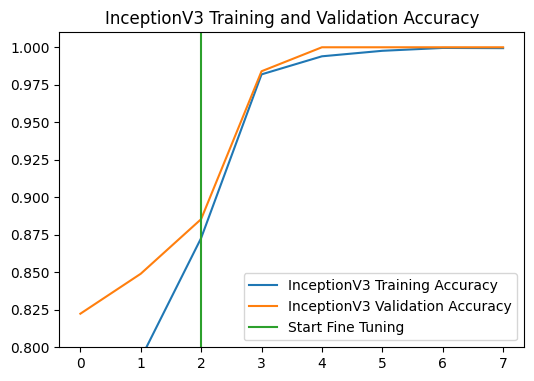

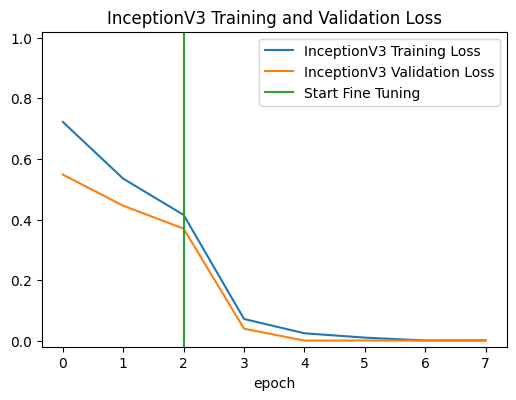

In [254]:
plt.figure(figsize=(6, 9))
plt.subplot(2, 1, 1)
plt.plot(acc_InceptionV3, label='InceptionV3 Training Accuracy')
plt.plot(val_acc_InceptionV3, label='InceptionV3 Validation Accuracy')
plt.ylim([0.8, 1.01])
plt.plot([initial_epochs-1,initial_epochs-1],
          plt.ylim(), label='Start Fine Tuning')
plt.legend(loc='lower right')
plt.title('InceptionV3 Training and Validation Accuracy')
plt.figure(figsize=(6, 9))
plt.subplot(2, 1, 2)
plt.plot(loss_InceptionV3, label='InceptionV3 Training Loss')
plt.plot(val_loss_InceptionV3, label='InceptionV3 Validation Loss')
plt.ylim([-0.02, 1.02])
plt.plot([initial_epochs-1,initial_epochs-1],
         plt.ylim(), label='Start Fine Tuning')
plt.legend(loc='upper right')
plt.title('InceptionV3 Training and Validation Loss')
plt.xlabel('epoch')

training_history = {}
training_history['train_loss'] = history_InceptionV3.history['loss']
training_history['val_loss'] = history_InceptionV3.history['val_loss']
training_history['train_acc'] = history_InceptionV3.history['accuracy']
training_history['val_acc'] = history_InceptionV3.history['val_accuracy']

with open('InceptionV3_TL+ORG.pkl', 'wb') as file:
    pickle.dump(training_history, file)
plt.savefig('InceptionV3_TL+ORG.pdf', format='pdf', dpi=300)
plt.savefig('InceptionV3_TL+ORG.svg', format='svg')
plt.savefig('InceptionV3_TL+ORG.png', format='png', dpi=300)
plt.show()

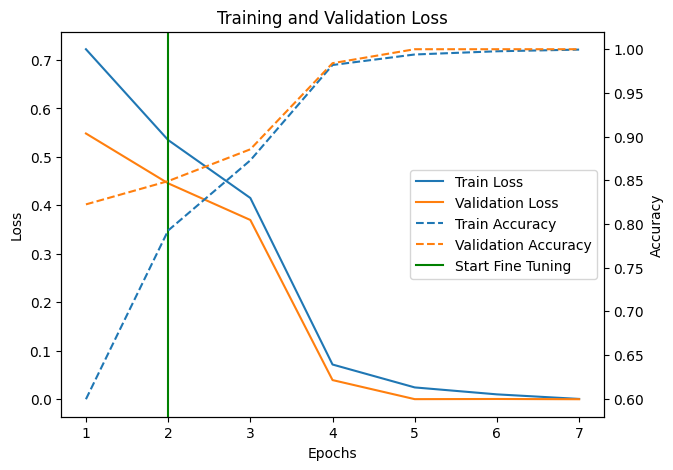

In [255]:
actual_epochs = range(1, total_epochs + 1)
actual_train_loss = loss_InceptionV3[:total_epochs]  
actual_val_loss = val_loss_InceptionV3[:total_epochs]  
actual_train_accuracy = acc_InceptionV3[:total_epochs]  
actual_val_accuracy = val_acc_InceptionV3[:total_epochs]

fig, ax1 = plt.subplots(figsize=(7, 5))
ax1.plot(actual_epochs, actual_train_loss, '-', label='Train Loss')
ax1.plot(actual_epochs, actual_val_loss, '-', label='Validation Loss')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.set_title('Training and Validation Loss')

ax2 = ax1.twinx()
ax2.plot(actual_epochs, actual_train_accuracy, '--', label='Train Accuracy')
ax2.plot(actual_epochs, actual_val_accuracy, '--', label='Validation Accuracy')
ax2.set_ylabel('Accuracy')
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
custom_legend_elements = handles1 + handles2 + [plt.Line2D([0], [0], color='green', label='Start Fine Tuning')]
custom_legend_labels = labels1 + labels2 + ['Start Fine Tuning']
ax1.legend(custom_legend_elements, custom_legend_labels, loc='center right')
ax1.axvline(x=initial_epochs - 1, color='green')
plot_data = {'fig': fig, 'ax1': ax1, 'ax2': ax2}

learning_curve_data = {
    'train_loss': actual_train_loss,
    'val_loss': actual_val_loss,
    'train_acc': actual_train_accuracy,
    'val_acc': actual_val_accuracy
}

with open('InceptionV3+Start Fine Tuning.pkl', 'wb') as file:
    pickle.dump(plot_data, file)
plt.savefig('InceptionV3+Start Fine Tuning.pdf', format='pdf', dpi=300)
plt.savefig('InceptionV3+Start Fine Tuning.svg', format='svg')
plt.savefig('InceptionV3+Start Fine Tuning.png', format='png', dpi=300)
plt.show()

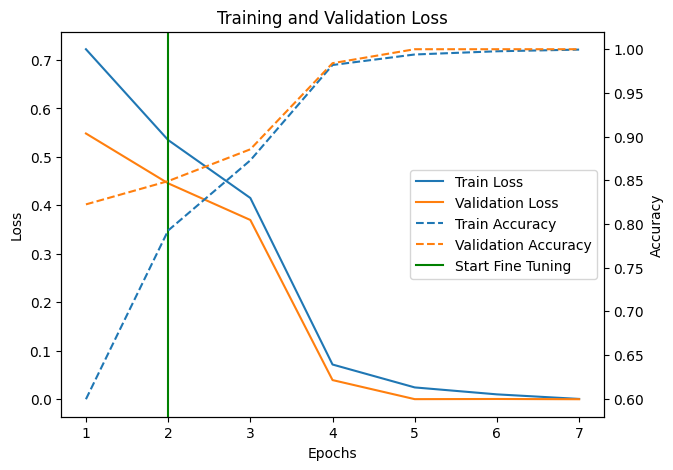

Training Loss: [0.7221012115478516, 0.5347427129745483, 0.4151933789253235, 0.07164204865694046, 0.02438431978225708, 0.010062058456242085, 0.0006344393477775156]
Validation Loss: [0.5482763051986694, 0.4454450011253357, 0.3698190450668335, 0.03953194618225098, 0.00018376031948719174, 0.0005363618256524205, 3.990231562056579e-05]
Training Accuracy: [0.5993537902832031, 0.7924805283546448, 0.8728153705596924, 0.9819356799125671, 0.9939785599708557, 0.997650146484375, 0.9995594024658203]
Validation Accuracy: [0.8223801255226135, 0.8490231037139893, 0.885435163974762, 0.9840142130851746, 1.0, 1.0, 1.0]


In [256]:
with open('InceptionV3+Start Fine Tuning.pkl', 'rb') as file:
    learning_curve = pickle.load(file)
fig = learning_curve['fig']
ax1 = learning_curve['ax1']
ax2 = learning_curve['ax2']
plt.show()

train_loss = learning_curve_data['train_loss']
val_loss = learning_curve_data['val_loss']
train_acc = learning_curve_data['train_acc']
val_acc = learning_curve_data['val_acc']
print("Training Loss:", learning_curve_data['train_loss'])
print("Validation Loss:", learning_curve_data['val_loss'])
print("Training Accuracy:", learning_curve_data['train_acc'])
print("Validation Accuracy:", learning_curve_data['val_acc'])

## Test_ds (InceptionV3) + TL

Predictions:
 [0 0 0 1 0 0 0 1 1 1 0 0 0 1 1 1 0 0 1 0 1 0 0 0 1 1 0 1 0 1 0 0 1 1 0 1 0
 1 1 1 0 0 1 0 0 0 0 0 0 1 1 0 1 0 0 1 0 0 0 1 0 1 0 0 0 1 0 0 0 1 0 0 1 1
 0 1 1 0 0 1 1 1 1 1 0 1 1 1 0 0 0 0 1 1 0 1 1 1 0 1 1 1 0 1 1 0 1 0 0 0 0
 0 1 0 1 0 0 1 0 1 0 1 0 0 0 1 0 1 0 0 1 1 1 0 1 1 0 0 0 0 1 0 0 0 1 0 0 0
 0 1 0 0 0 0 1 0 1 0 0 0 0 1 0 0 1 1 0 0 0 0 0 1 0 1 0 0 1 1 0 1 0 1 0 0 0
 1 0 0 1 0 0 1 1 1 1 1 1 0 0 0 0 1 0 1 0 1 0 1 1 1 0 0 0 0 0 1 0 1 0 1 0 1
 0 0 0 0 1 1 0 1 0 1 0 0 1 1 0 0 0 0 0 1 0 1 0 0 1 1 0 0 0 0 0 0 1 1 1 0 1
 1 1 0 1 1 0 0 0 1 0 1 1 0 0 0 0 1 1 1 1 1 1 1 0 0 1 0 1 1 0 0 1 0 0 0 1 0
 1 0 0 0 0 0 0 0 1 1 0 1 1 1 0 1 1 0 1 0 1 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 1
 0 0 0 0 0 1 0 1 0 1 0 0 0 1 0 0 0 0 0 1 1 1 1 1 0 1 0 0 1 0 0 1 0 1 0 1 0
 0 1 0 1 0 1 0 1 1 0 0 0 0 0 1 0 1 0 0 0 1 1 1 1 0 0 1 1 0 1 0 0 0 1 0 1 1
 0 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0 0 1 0 1 1 1 0 1 0 0 1 0 0 1 1 0 0 1 0 1 0
 0 0 1 0 1 1 1 0 0 0 0 0 1 0 1 1 0 0 1 1 0 1 1 1 0 1 1 0 0 0 0 1 0 0 0 0 1
 0 1 1 1 0 

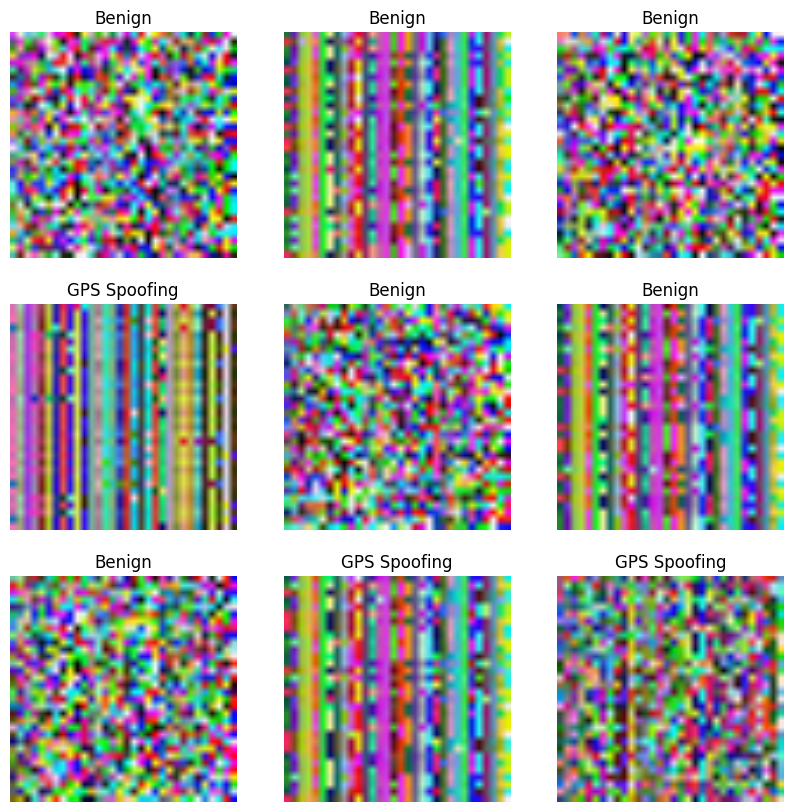

In [257]:
all_predictions_InceptionV3 = []
all_labels_InceptionV3 = []

for image_batch, label_batch in test_ds.as_numpy_iterator():
    predictions = model_InceptionV3.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_InceptionV3.append(predictions)
    all_labels_InceptionV3.append(label_batch)

all_predictions_InceptionV3 = np.concatenate(all_predictions_InceptionV3)
all_labels_InceptionV3 = np.concatenate(all_labels_InceptionV3)
print('Predictions:\n', all_predictions_InceptionV3)
print('Labels:\n', all_labels_InceptionV3)

report_InceptionV3 = classification_report(all_labels_InceptionV3, all_predictions_InceptionV3, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_InceptionV3[i]])
    plt.axis("off")

test_ds (InceptionV3)
                  
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00       336
GPS Spoofing       1.00      1.00      1.00       240

    accuracy                           1.00       576
   macro avg       1.00      1.00      1.00       576
weighted avg       1.00      1.00      1.00       576

                  
1) Accuracy: 1.0
                  
2) Precision: 1.0
                  
3) Recall: 1.0
                  
4) Average F1-score: 1.0
                  
5) F1-score for each type of attack: [1. 1.]
                  
6) Average ROC AUC: 1.0
                  
7) Average PR AUC: 1.0
                  
8) Balanced Accuracy: 1.0
                  
9) Hinge: 0.5833333333333334
                  
10) Matthews Correlation Coefficient: 1.0
                  
11) Jaccard Score: 1.0
                  
12) Log Loss: 2.2204460492503136e-16
                  
13) Zero-One Loss 0.0
                  
14) Prediction Overh

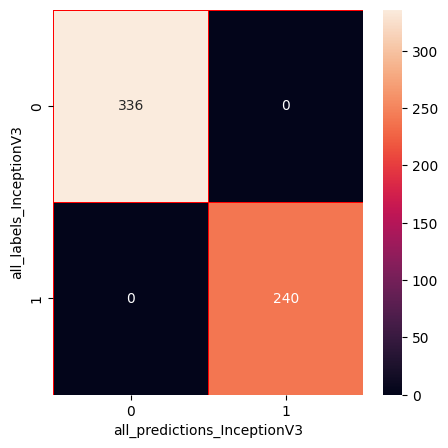

In [258]:
print("test_ds (InceptionV3)")
print("                  ")
print(report_InceptionV3)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_InceptionV3 , all_predictions_InceptionV3)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_InceptionV3, all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_InceptionV3, all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_InceptionV3 ,all_predictions_InceptionV3)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_InceptionV3")
plt.ylabel("all_labels_InceptionV3")
plt.show()

In [259]:
loss_test_InceptionV3, accuracy_test_InceptionV3 = model_InceptionV3.evaluate(test_ds)
print("Test loss: {:.4f}".format(loss_test_InceptionV3))
print("Test accuracy: {:.4f}".format(accuracy_test_InceptionV3))

18/18 [==============================] - 1s 31ms/step - loss: 3.0851e-05 - accuracy: 1.0000
Test loss: 0.0000
Test accuracy: 1.0000


In [260]:
saved_info = {
    'class_names': class_names,
    'all_labels_InceptionV3': all_labels_InceptionV3,
    'all_predictions_InceptionV3': all_predictions_InceptionV3,
    'cm': cm,
    'accuracy_score': accuracy_score(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'precision_score': precision_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'recall_score': recall_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'f1_score_weighted': f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'f1_score_each': f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Hinge': hinge_loss(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Jaccard Score': jaccard_score(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Log Loss': log_loss(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Zero-One Loss': zero_one_loss(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('InceptionV3_test(TL)_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [261]:
#=========

In [262]:
with open('InceptionV3_test(TL)_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)

print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_labels_InceptionV3'])
print("  ")
print("predictions:", saved_info['all_predictions_InceptionV3'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [0 0 0 1 0 0 0 1 1 1 0 0 0 1 1 1 0 0 1 0 1 0 0 0 1 1 0 1 0 1 0 0 1 1 0 1 0
 1 1 1 0 0 1 0 0 0 0 0 0 1 1 0 1 0 0 1 0 0 0 1 0 1 0 0 0 1 0 0 0 1 0 0 1 1
 0 1 1 0 0 1 1 1 1 1 0 1 1 1 0 0 0 0 1 1 0 1 1 1 0 1 1 1 0 1 1 0 1 0 0 0 0
 0 1 0 1 0 0 1 0 1 0 1 0 0 0 1 0 1 0 0 1 1 1 0 1 1 0 0 0 0 1 0 0 0 1 0 0 0
 0 1 0 0 0 0 1 0 1 0 0 0 0 1 0 0 1 1 0 0 0 0 0 1 0 1 0 0 1 1 0 1 0 1 0 0 0
 1 0 0 1 0 0 1 1 1 1 1 1 0 0 0 0 1 0 1 0 1 0 1 1 1 0 0 0 0 0 1 0 1 0 1 0 1
 0 0 0 0 1 1 0 1 0 1 0 0 1 1 0 0 0 0 0 1 0 1 0 0 1 1 0 0 0 0 0 0 1 1 1 0 1
 1 1 0 1 1 0 0 0 1 0 1 1 0 0 0 0 1 1 1 1 1 1 1 0 0 1 0 1 1 0 0 1 0 0 0 1 0
 1 0 0 0 0 0 0 0 1 1 0 1 1 1 0 1 1 0 1 0 1 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 1
 0 0 0 0 0 1 0 1 0 1 0 0 0 1 0 0 0 0 0 1 1 1 1 1 0 1 0 0 1 0 0 1 0 1 0 1 0
 0 1 0 1 0 1 0 1 1 0 0 0 0 0 1 0 1 0 0 0 1 1 1 1 0 0 1 1 0 1 0 0 0 1 0 1 1
 0 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0 0 1 0 1 1 1 0 1 0 0 1 0 0 1 1 0 0 1 0 1 0
 0 0 1 0 1 1 1 0 0 0 0 0 1 0 1 1 0 0 1 1 0 1 1 1 0 1 1 0 0 0 0 1 0

## Val_ds + (InceptionV3) + TL

Predictions:
 [1 0 1 ... 1 0 1]
Labels:
 [1 0 1 ... 1 0 1]


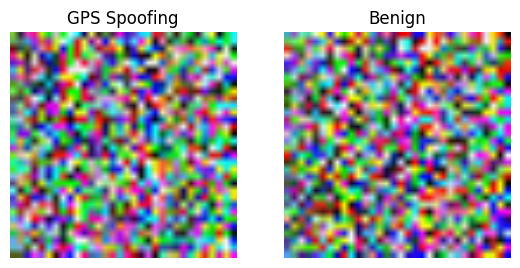

In [263]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_InceptionV3 = []
all_labels_InceptionV3 = []

for image_batch, label_batch in val_ds.as_numpy_iterator():
    predictions = model_InceptionV3.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_InceptionV3.append(predictions)
    all_labels_InceptionV3.append(label_batch)

all_predictions_InceptionV3 = np.concatenate(all_predictions_InceptionV3)
all_labels_InceptionV3 = np.concatenate(all_labels_InceptionV3)
print('Predictions:\n', all_predictions_InceptionV3)
print('Labels:\n', all_labels_InceptionV3)

report_InceptionV3 = classification_report(all_labels_InceptionV3, all_predictions_InceptionV3, target_names=class_names_s)

plt.figure(figsize=(10, 10))
for i in range(2):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_InceptionV3[i]])
    plt.axis("off")

val_ds (InceptionV3)
                  
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00       648
GPS Spoofing       1.00      1.00      1.00       478

    accuracy                           1.00      1126
   macro avg       1.00      1.00      1.00      1126
weighted avg       1.00      1.00      1.00      1126

                  
1) Accuracy: 1.0
                  
2) Precision: 1.0
                  
3) Recall: 1.0
                  
4) Average F1-score: 1.0
                  
5) F1-score for each type of attack: [1. 1.]
                  
6) Average ROC AUC: 1.0
                  
7) Average PR AUC: 1.0
                  
8) Balanced Accuracy: 1.0
                  
9) Hinge: 0.5754884547069272
                  
10) Matthews Correlation Coefficient: 1.0
                  
11) Jaccard Score: 1.0
                  
12) Log Loss: 2.2204460492503136e-16
                  
13) Zero-One Loss 0.0
                  
14) Prediction Overhe

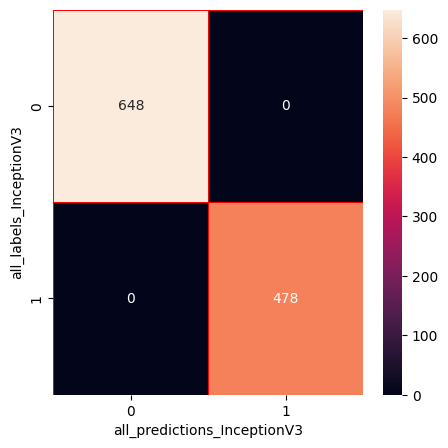

In [264]:
print("val_ds (InceptionV3)")
print("                  ")
print(report_InceptionV3)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_InceptionV3 , all_predictions_InceptionV3)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_InceptionV3, all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_InceptionV3, all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_InceptionV3 ,all_predictions_InceptionV3)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_InceptionV3")
plt.ylabel("all_labels_InceptionV3")
plt.show()

In [265]:
loss_val_InceptionV3, accuracy_val_InceptionV3 = model_InceptionV3.evaluate(val_ds)
print("Validation Loss: {:.4f}".format(loss_val_InceptionV3))
print("Validation Accuracy: {:.4f}".format(accuracy_val_InceptionV3))

36/36 [==============================] - 1s 30ms/step - loss: 2.6413e-05 - accuracy: 1.0000
Validation Loss: 0.0000
Validation Accuracy: 1.0000


In [266]:
saved_info = {
    'class_names': class_names,
    'all_labels_InceptionV3': all_labels_InceptionV3,
    'all_predictions_InceptionV3': all_predictions_InceptionV3,
    'cm': cm,
    'accuracy_score': accuracy_score(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'precision_score': precision_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'recall_score': recall_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'f1_score_weighted': f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'f1_score_each': f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Hinge': hinge_loss(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Jaccard Score': jaccard_score(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Log Loss': log_loss(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Zero-One Loss': zero_one_loss(all_labels_InceptionV3 , all_predictions_InceptionV3),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('InceptionV3_val(TL)_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [267]:
#=========

In [268]:
with open('InceptionV3_val(TL)_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)

print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_labels_InceptionV3'])
print("  ")
print("predictions:", saved_info['all_predictions_InceptionV3'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [1 0 1 ... 1 0 1]
  
predictions: [1 0 1 ... 1 0 1]
  
cm: [[648   0]
 [  0 478]]
  
1) Accuracy: 1.0
  
2) Precision: 1.0
  
3) Recall: 1.0
  
4) Average F1-score: 1.0
  
5) F1-score for each type of attack: [1. 1.]
  
6) Average ROC AUC: 1.0
  
7) Average PR AUC: 1.0
  
8) Balanced Accuracy: 0.9905956112852664
  
9) Hinge: 0.5754884547069272
  
10) Matthews Correlation Coefficient: 1.0
  
11) Jaccard Score: 1.0
  
12) Log Loss: 2.2204460492503136e-16
  
13) Zero-One Loss: 0.0
  
14) Prediction Overhead: 0.4288194444444444
  
15) Specificity: 0.9905956112852664


## Load the saved model and learning curve

In [269]:
new_model = tf.keras.models.load_model('./InceptionV3+TL.h5')

In [270]:
for layer in new_model.layers:
    print(layer.name)
    weights = layer.get_weights()
    for weight in weights:
        print(weight)

input_36
sequential
tf.math.truediv_17
tf.math.subtract_17
inception_v3
[[[[-4.59105551e-01 -4.14526574e-02 -3.62577499e-03 -9.87672508e-02
    -3.37070860e-02  4.79929037e-02  2.32542142e-01  3.23927671e-01
     5.90160079e-02  9.47738215e-02  4.24996056e-02  1.26620471e-01
     1.33215979e-01  1.22741833e-01 -7.92686343e-02  2.08227970e-02
    -1.99647829e-01 -3.02687973e-01 -2.10659921e-01 -3.52898419e-01
    -5.58023095e-01  3.20223093e-01  4.53596050e-03 -3.09266411e-02
    -6.86957911e-02  2.00968519e-01  1.14542745e-01  2.40372881e-01
     1.52943470e-02  5.96231259e-02 -5.85714653e-02  8.78173351e-01]
   [ 3.16376328e-01 -4.78494260e-03 -6.84681814e-03  7.44503662e-02
    -1.97458476e-01  5.20143658e-02 -1.24460436e-01  3.36123914e-01
     3.01678218e-02 -1.26477107e-01 -1.05597451e-01 -5.31241074e-02
    -2.43102223e-01  1.66047230e-01 -1.03186309e-01 -6.55613691e-02
     2.60930099e-02  1.16658449e-01 -1.60814777e-01 -3.49688202e-01
    -7.33594477e-01  3.11471581e-01  1.3300

In [271]:
print(new_model.get_config())

{'name': 'model_17', 'trainable': True, 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_input_shape': (None, 224, 224, 3), 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'input_36'}, 'registered_name': None, 'name': 'input_36', 'inbound_nodes': []}, {'module': 'keras', 'class_name': 'Sequential', 'config': {'name': 'sequential', 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_input_shape': (None, 224, 224, 3), 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'random_flip_input'}, 'registered_name': None}, {'module': 'keras.layers', 'class_name': 'RandomFlip', 'config': {'name': 'random_flip', 'trainable': True, 'dtype': 'float32', 'mode': 'horizontal_and_vertical', 'seed': None}, 'registered_name': None, 'build_config': {'input_shape': (None, 224, 224, 3)}}, {'module': 'keras.layers', 'class_name': 'RandomRotation', 'config': {'name': 'random_rotation', 'trainable': True, 'dtype': 'float